# Inverse Kinematics of the ABB IRB2400

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import glob, os
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

path = kagglehub.dataset_download("luisatencio/abb-irb-2400-arm-robot-kinematics-dataset")
print("Path to dataset files:", path)
print("Files found:", os.listdir(path))

Path to dataset files: /home/paolo/.cache/kagglehub/datasets/luisatencio/abb-irb-2400-arm-robot-kinematics-dataset/versions/1
Files found: ['datasetIRB2400.csv']


In [ ]:
csv_files = glob.glob(os.path.join(path, '*.csv'))
assert len(csv_files) >= 1, "No CSV file found, check os.listdir(path) above"
data = pd.read_csv(csv_files[0])
print("Loaded:", csv_files[0])
print(data.columns.tolist())
data.head()

Loaded: /home/paolo/.cache/kagglehub/datasets/luisatencio/abb-irb-2400-arm-robot-kinematics-dataset/versions/1/datasetIRB2400.csv
['x', 'y', 'z', 'yaw', 'pitch', 'roll', 'q1_in', 'q2_in', 'q3_in', 'q4_in', 'q5_in', 'q6_in', 'q1_out', 'q2_out', 'q3_out', 'q4_out', 'q5_out', 'q6_out']


,x,y,z,yaw,pitch,roll,q1_in,q2_in,q3_in,q4_in,q5_in,q6_in,q1_out,q2_out,q3_out,q4_out,q5_out,q6_out
0,-80.9148,-121.7499,1896.4867,-0.6941,0.9229,-1.4411,-2.2407,-0.7975,0.6551,-3.2989,1.1212,5.7052,-2.2347,-0.8949,0.6113,-3.2841,1.2117,5.6792
1,-80.9148,-121.7499,1896.4867,-0.6941,0.9229,-1.4411,-2.2233,-0.8511,0.5966,-3.2320,1.1662,5.6429,-2.2347,-0.8949,0.6113,-3.2841,1.2117,5.6792
2,-80.9148,-121.7499,1896.4867,-0.6941,0.9229,-1.4411,-2.2567,-0.9468,0.5820,-3.3165,1.1220,5.5944,-2.2347,-0.8949,0.6113,-3.2841,1.2117,5.6792
3,-80.9148,-121.7499,1896.4867,-0.6941,0.9229,-1.4411,-2.1557,-0.8205,0.5532,-3.1993,1.2697,5.7474,-2.2347,-0.8949,0.6113,-3.2841,1.2117,5.6792
4,-80.9148,-121.7499,1896.4867,-0.6941,0.9229,-1.4411,-2.3267,-0.9279,0.6722,-3.2867,1.2266,5.6304,-2.2347,-0.8949,0.6113,-3.2841,1.2117,5.6792


## Evaluation utility

* prints overall + per-joint MAE/MSE/R&sup2;
* draws a True-vs-Predicted / Absolute-Error panel per output

In [ ]:
def quality(M, XT, YT):
  Yp = M.predict(XT)
  # Grab column names (e.g. q1_out..q6_out) before converting to numpy, so
  # the per-joint subplots below can be labeled.
  col_names = list(YT.columns) if hasattr(YT, 'columns') else None
  YT = np.asarray(YT)
  Yp = np.asarray(Yp)
  if YT.ndim == 1:
    YT = YT.reshape(-1, 1)
    Yp = Yp.reshape(-1, 1)
  n_outputs = YT.shape[1]
  if col_names is None:
    col_names = [f'y{i}' for i in range(n_outputs)]

  overall_mae = mean_absolute_error(YT, Yp)
  overall_mse = mean_squared_error(YT, Yp)
  overall_r2  = r2_score(YT, Yp)
  per_joint_r2 = {col_names[i]: r2_score(YT[:, i], Yp[:, i]) for i in range(n_outputs)}

  print('MAE: ' + format(overall_mae, ".4f"))
  print('MSE: ' + format(overall_mse, ".4f"))
  print('R2: ' + format(overall_r2, ".4f"))
  for name, v in per_joint_r2.items():
    print('  ' + name + ' R2: ' + format(v, ".4f"))

  # One True-vs-Predicted / Absolute-Error column per output
  fig, ax = plt.subplots(nrows=2, ncols=n_outputs, figsize=(3.2 * n_outputs, 6.4), squeeze=False)
  for i in range(n_outputs):
    r2_i = per_joint_r2[col_names[i]]
    ax[0, i].plot(YT[:, i], Yp[:, i], 'b.', markersize=2, alpha=0.3)
    ax[0, i].plot(YT[:, i], YT[:, i], 'r')
    ax[0, i].set_xlabel('True')
    ax[0, i].set_ylabel('Predicted')
    ax[0, i].set_title(col_names[i] + ' (R2=' + format(r2_i, ".3f") + ')')
    ax[1, i].hist(np.abs(YT[:, i] - Yp[:, i]), 50)
    ax[1, i].set_xlabel('Absolute Error')
    ax[1, i].set_ylabel('Frequency')
  fig.tight_layout()

  return {'MAE': overall_mae, 'MSE': overall_mse, 'R2': overall_r2, 'R2_per_joint': per_joint_r2}

In [ ]:
in_cols  = ['q1_in', 'q2_in', 'q3_in', 'q4_in', 'q5_in', 'q6_in']
out_cols = ['q1_out', 'q2_out', 'q3_out', 'q4_out', 'q5_out', 'q6_out']

diff = data[out_cols].to_numpy() - data[in_cols].to_numpy()
out_var = data[out_cols].var().to_numpy()
diff_var = diff.var(axis=0)

leakage_summary = pd.DataFrame({
    'q_out variance': out_var,
    '(q_out - q_in) variance': diff_var,
    'variance ratio (perturbation / output)': diff_var / out_var,
    'corr(q_in, q_out)': [np.corrcoef(data[ic], data[oc])[0, 1] for ic, oc in zip(in_cols, out_cols)],
}, index=[f'q{i+1}' for i in range(6)])
leakage_summary

,q_out variance,(q_out - q_in) variance,variance ratio (perturbation / output),"corr(q_in, q_out)"
q1,3.299037,0.003340,0.001012,0.999494
q2,1.113440,0.003330,0.002991,0.998507
q3,0.396191,0.003332,0.008409,0.995823
q4,4.079248,0.003330,0.000816,0.999592
q5,1.462204,0.003337,0.002282,0.998861
q6,16.224013,0.003334,0.000205,0.999897


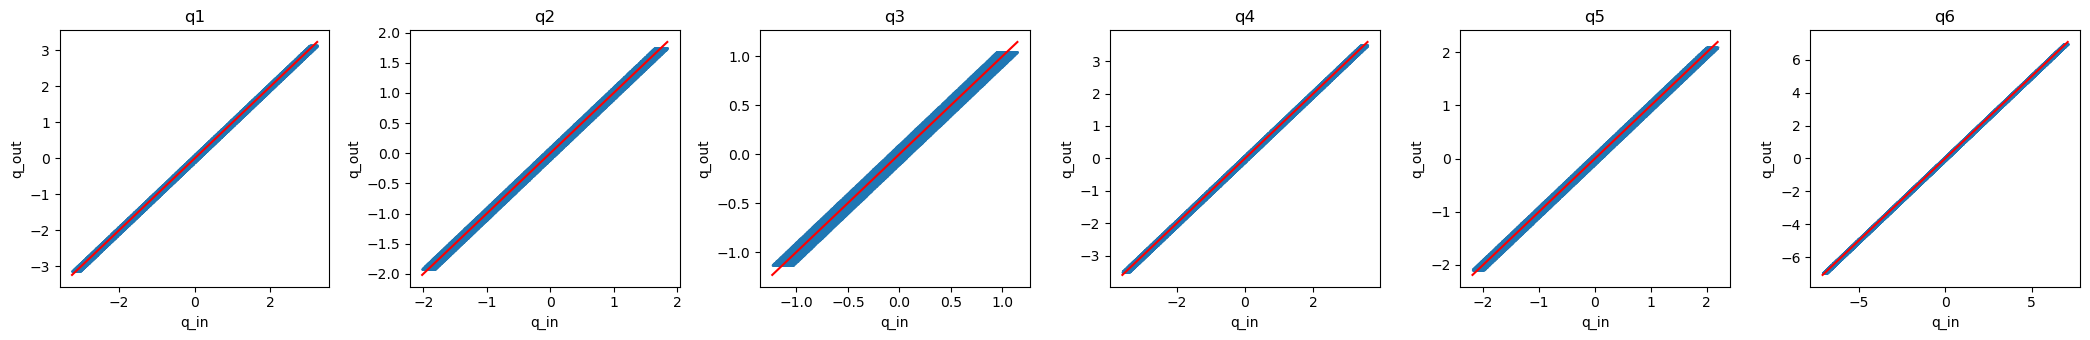

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=6, figsize=(21, 3.5))
for i in range(6):
    xi = data[in_cols[i]].to_numpy()
    yi = data[out_cols[i]].to_numpy()
    ax[i].plot(xi, yi, '.', markersize=1, alpha=0.2)
    lo = min(xi.min(), yi.min())
    hi = max(xi.max(), yi.max())
    ax[i].plot([lo, hi], [lo, hi], 'r')
    ax[i].set_title(f'q{i+1}')
    ax[i].set_xlabel('q_in')
    ax[i].set_ylabel('q_out')
fig.tight_layout()

## Model learns q_out from q_in: confirmed by a simple fit with Ridge

If a plain Ridge regression trained on `q_in` **only**, no pose information at all, already gets a high R&sup2;: that is direct evidence `q_in` "leaks"
the answer

alpha best: 133.3521432163324
MAE: 0.0499
MSE: 0.0033
R2: 0.9974
  q1_out R2: 0.9990
  q2_out R2: 0.9970
  q3_out R2: 0.9917
  q4_out R2: 0.9992
  q5_out R2: 0.9977
  q6_out R2: 0.9998


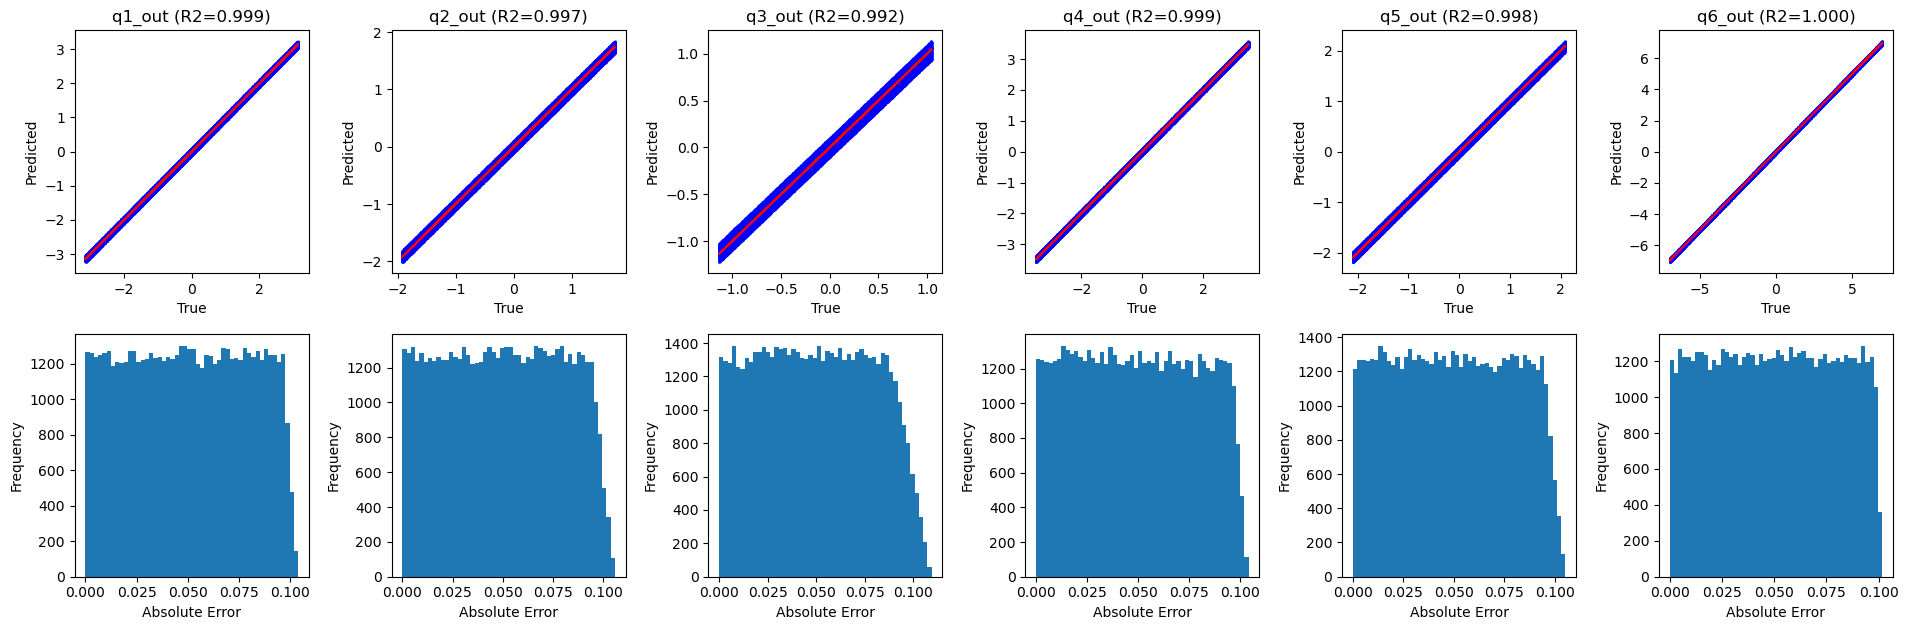

In [ ]:
from sklearn.linear_model import Ridge

Xin_train, Xin_test, Yin_train, Yin_test = train_test_split(
    data[in_cols], data[out_cols], test_size=0.2, random_state=42)

leak_model = GridSearchCV(estimator=Ridge(), param_grid={'alpha': np.logspace(-4, 3, 9)},
                           cv=3, scoring='neg_mean_absolute_error')
leak_model.fit(Xin_train, Yin_train)
print('alpha best:', leak_model.best_params_['alpha'])
quality(leak_model, Xin_test, Yin_test);

**Conclusion:** the perturbation variance is tiny compared to the spread of `q_out`
(see the ratio column above) and the fit above lands on essentially a perfect diagonal for
every joint using `q_in` alone. `q_in` is therefore dropped from the inputs entirely. Once it
is gone, the rows that only differed in `q_in` become exact duplicates on
`(pose -> q_out)`, which is why the dataset collapses from 300,000 to a much smaller number
of unique poses below.

## Preprocessing

`pose_cols` (position + orientation) are the only inputs kept. As a sanity check, we also
verify that the same pose never maps to two different `q_out` (i.e. the mapping is
single-valued) before splitting and scaling.

In [ ]:
pose_cols = ['x', 'y', 'z', 'yaw', 'pitch', 'roll']
output_cols = ['q1_out', 'q2_out', 'q3_out', 'q4_out', 'q5_out', 'q6_out']

# Sanity check: does the same pose always map to the same q_out?
n_inconsistent = (data.groupby(pose_cols)[output_cols]
                       .nunique()
                       .gt(1)
                       .any(axis=1)
                       .sum())
print(f"Pose con q_out non univoco: {n_inconsistent}")

# Now that q_in is out of the picture, keep one row per unique pose.
data_clean = data.drop_duplicates(subset=pose_cols).reset_index(drop=True)
print(f"Righe originali: {len(data)}, righe uniche per posa: {len(data_clean)}")

x_raw = data_clean[pose_cols]
y = data_clean[output_cols]

x_train_raw, x_test_raw, y_train, y_test = train_test_split(x_raw, y, test_size=0.2, random_state=42)

# Fit the scaler on the training set only, then apply it to the test set,
# to avoid leaking test-set statistics into the training data.
scaler = MinMaxScaler()
x_train = scaler.fit_transform(x_train_raw)
x_test = scaler.transform(x_test_raw)

Pose con q_out non univoco: 0
Righe originali: 300000, righe uniche per posa: 15000


## Methods
* Ridge
* Kernel
* Ridge (RBF)
* SVR (RBF)
* Decision Tree
* Random Forest
* Gradient Boosting

All tuned with `GridSearchCV` and evaluated with `quality()`.

Kernel Ridge is tuned and fit on a 2000 samples subset because an exact kernel method needs an *n x n* kernel matrix and does not scale to the full training set.

In [ ]:
results = {}

def log_result(name, M, XT, YT):
    print(f'--- {name} ---')
    r = quality(M, XT, YT)
    results[name] = r
    return r

alpha best: 0.0001
--- Ridge ---
MAE: 1.4583
MSE: 4.2300
R2: 0.1085
  q1_out R2: 0.1235
  q2_out R2: 0.5297
  q3_out R2: 0.0011
  q4_out R2: -0.0038
  q5_out R2: 0.0011
  q6_out R2: -0.0008


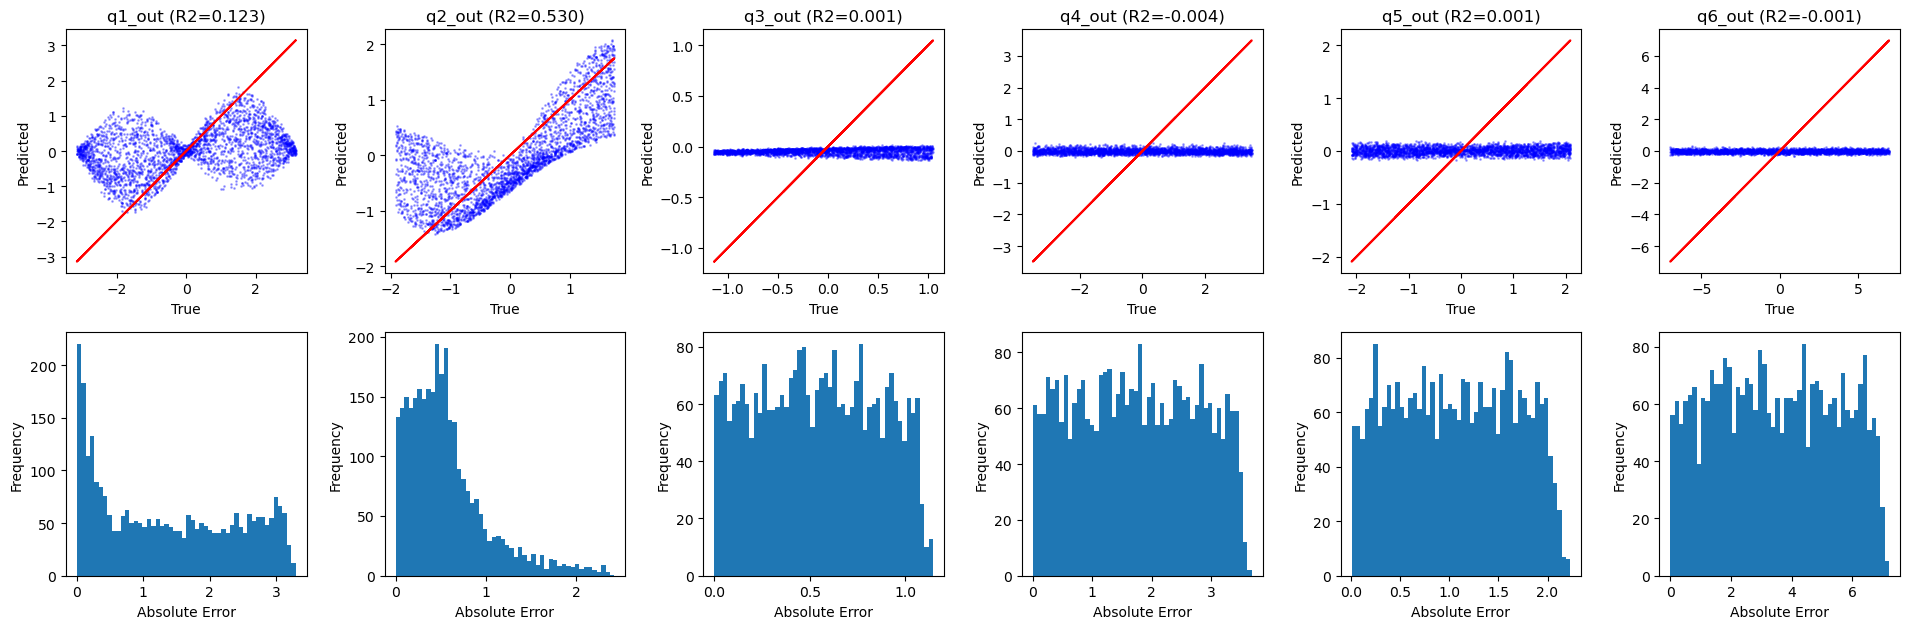

In [ ]:
from sklearn.linear_model import Ridge

grid = {'alpha': np.logspace(-4, 3, 9)}
M = GridSearchCV(estimator=Ridge(), param_grid=grid, cv=3, scoring='neg_mean_absolute_error')
M.fit(x_train, y_train)
print('alpha best:', M.best_params_['alpha'])
log_result('Ridge', M, x_test, y_test);

alpha best: 0.005623413251903491
gamma best: 0.31622776601683794
--- Kernel Ridge (RBF) ---
MAE: 1.3570
MSE: 4.1357
R2: 0.2980
  q1_out R2: 0.2950
  q2_out R2: 0.5987
  q3_out R2: 0.9834
  q4_out R2: -0.0367
  q5_out R2: -0.0339
  q6_out R2: -0.0186


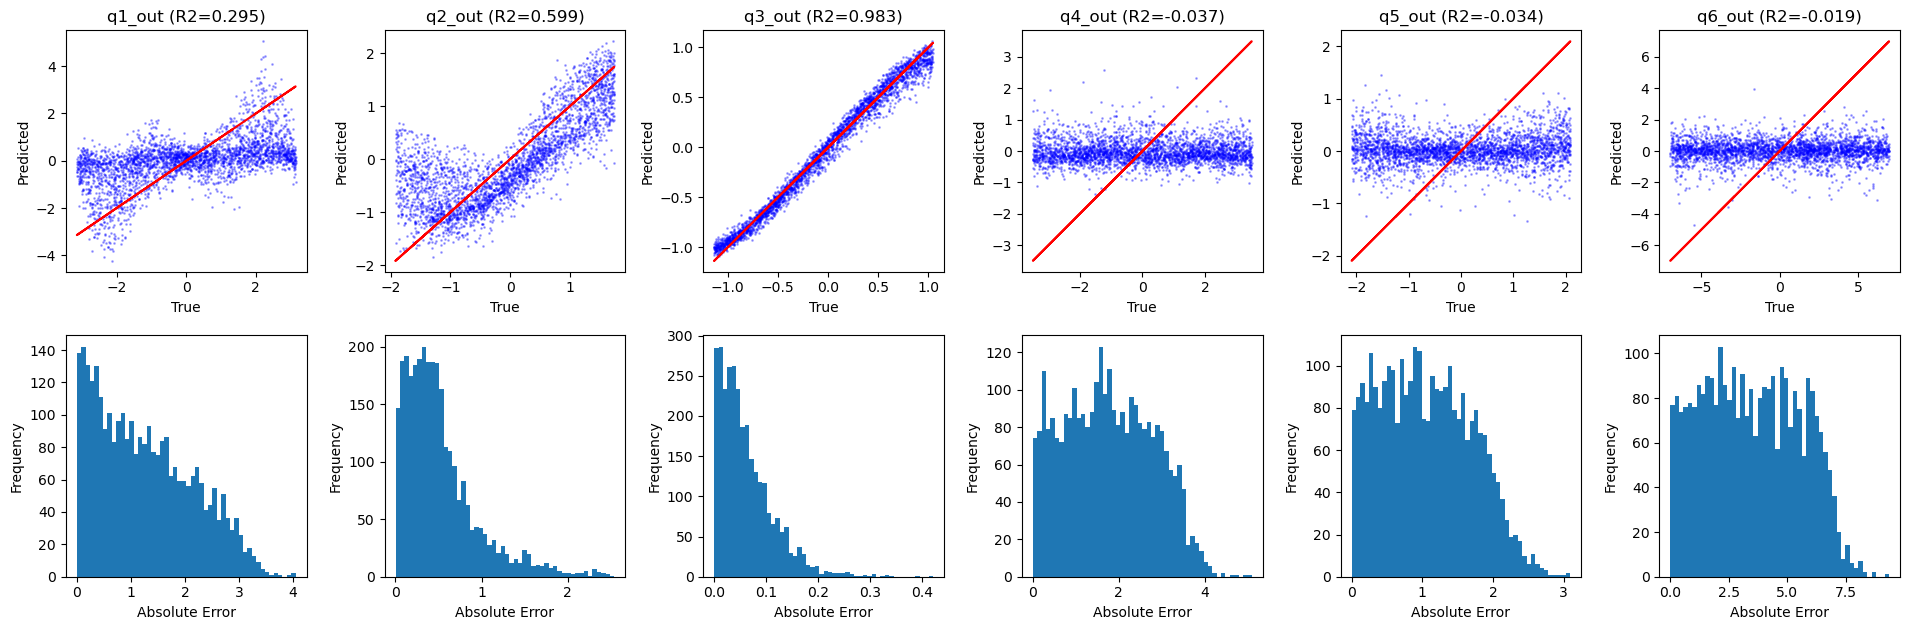

In [ ]:
from sklearn.kernel_ridge import KernelRidge

# Subset 2,000-row, same used for SVR
grid = {'alpha': np.logspace(-4, 3, 5), 'kernel': ['rbf'], 'gamma': np.logspace(-4, 3, 5)}
M = GridSearchCV(estimator=KernelRidge(), param_grid=grid, cv=3, scoring='neg_mean_absolute_error')
M.fit(x_train[:2000], y_train[:2000])
print('alpha best:', M.best_params_['alpha'])
print('gamma best:', M.best_params_['gamma'])
log_result('Kernel Ridge (RBF)', M, x_test, y_test);

Grid search on a 2,000-row subset...
Best params: {'estimator__C': 1, 'estimator__epsilon': 0.1, 'estimator__gamma': 'scale', 'estimator__kernel': 'rbf'}
Refitting best config on the full training set...
--- SVR (RBF) ---
MAE: 1.3076
MSE: 4.1568
R2: 0.2877
  q1_out R2: 0.3502
  q2_out R2: 0.6085
  q3_out R2: 0.9889
  q4_out R2: -0.0461
  q5_out R2: -0.1498
  q6_out R2: -0.0258


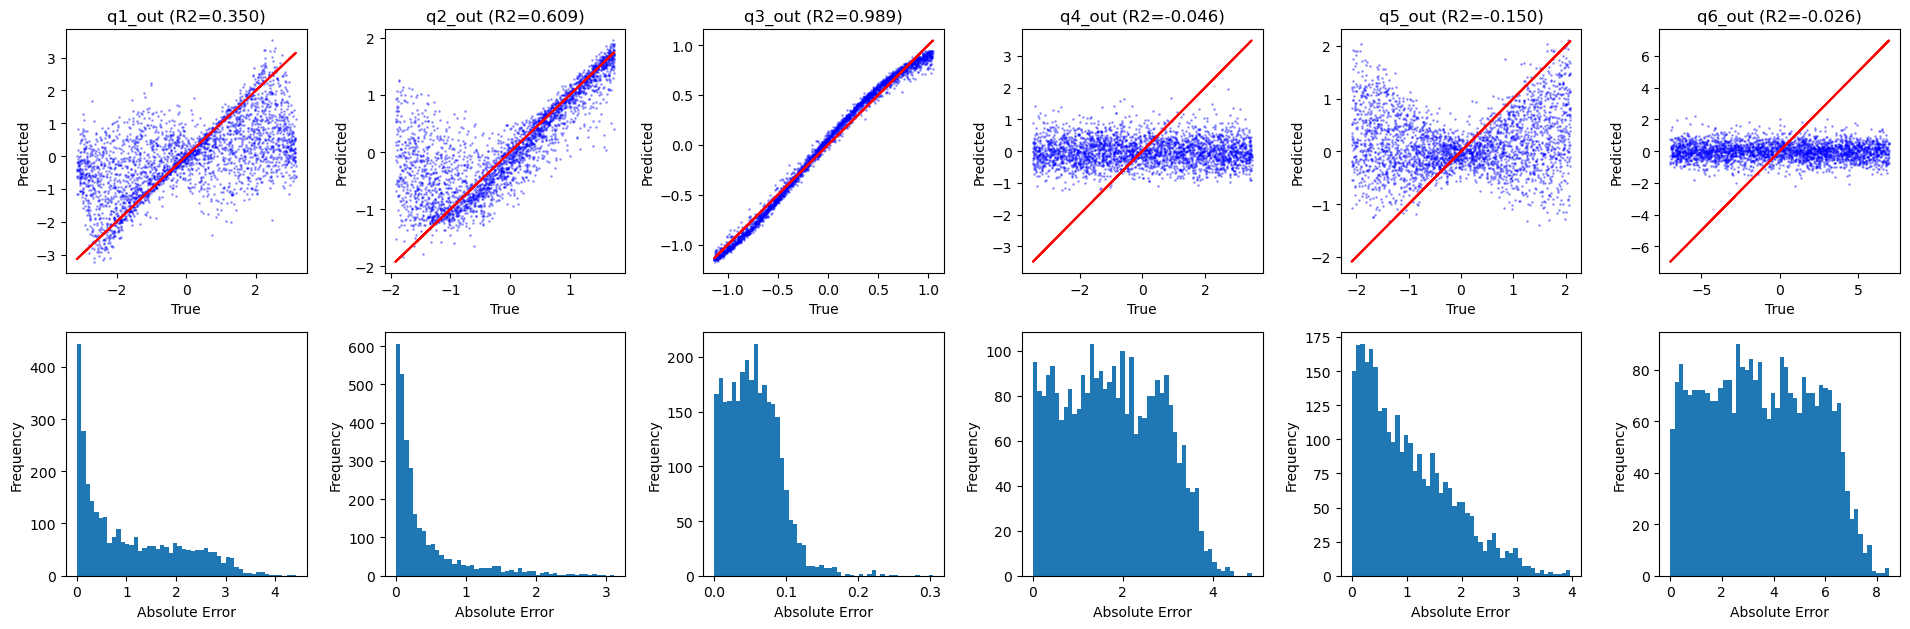

In [ ]:
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor

svr_estimator = MultiOutputRegressor(SVR(cache_size=1000))
grid = {
    'estimator__C':       [1, 10, 100, 1000],
    'estimator__gamma':   ['scale', 0.1, 0.01],
    'estimator__kernel':  ['rbf'],
    'estimator__epsilon': [0.1],
}
M = GridSearchCV(estimator=svr_estimator, param_grid=grid, cv=3, n_jobs=-1,
                  scoring='neg_mean_absolute_error')

print("Grid search on a 2,000-row subset...")
M.fit(x_train[:2000], y_train[:2000])
print("Best params:", M.best_params_)

print("Refitting best config on the full training set...")
best_svr = M.best_estimator_
best_svr.fit(x_train, y_train)
log_result('SVR (RBF)', best_svr, x_test, y_test);

min_samples_leaf best: 24
--- Decision Tree ---
MAE: 1.3720
MSE: 4.4019
R2: 0.2483
  q1_out R2: 0.3652
  q2_out R2: 0.5986
  q3_out R2: 0.7254
  q4_out R2: -0.0521
  q5_out R2: -0.0235
  q6_out R2: -0.1240


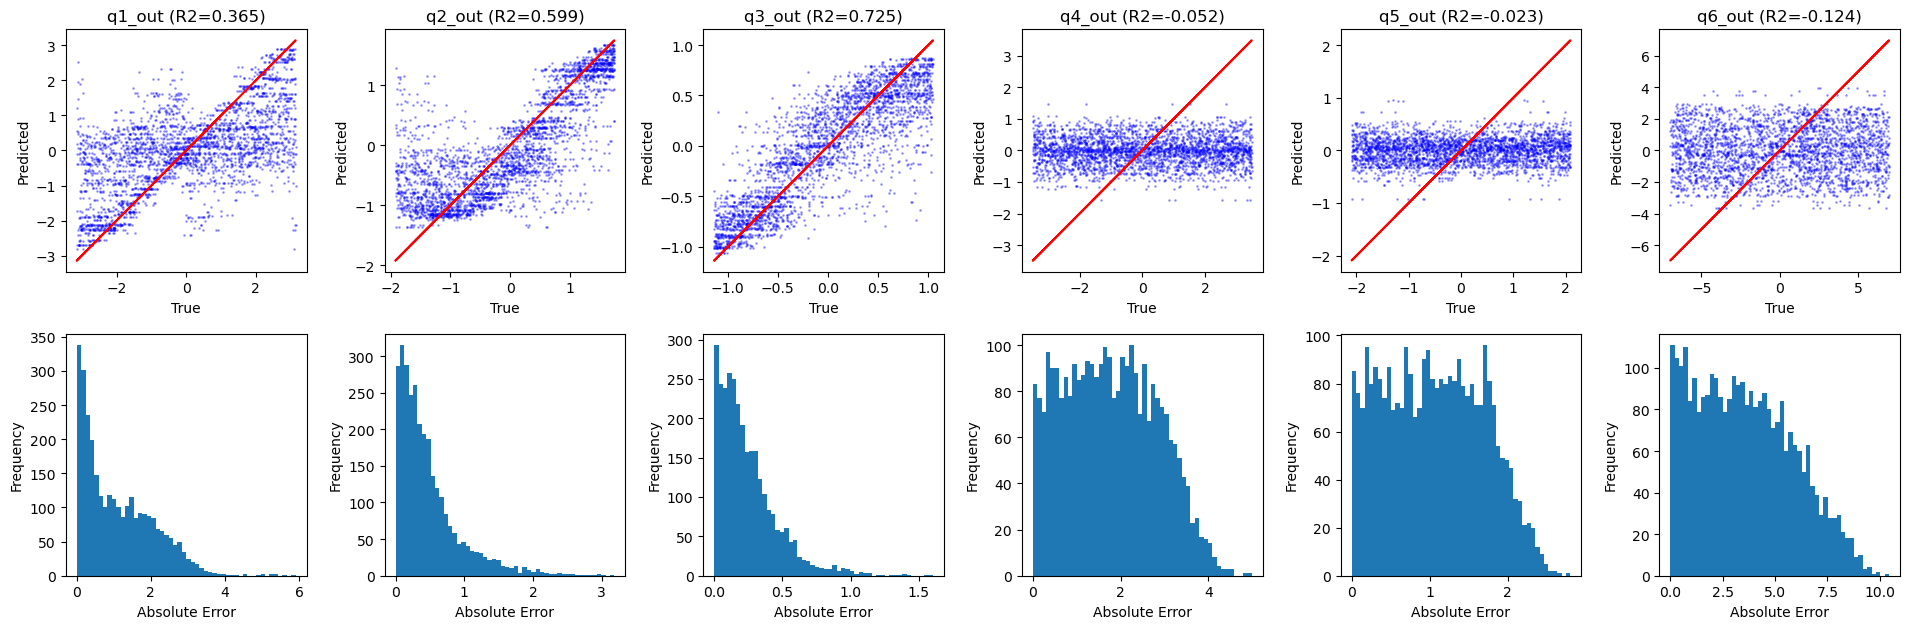

In [ ]:
from sklearn.tree import DecisionTreeRegressor

grid = {'min_samples_leaf': [2, 4, 6, 8, 12, 16, 20, 24]}
M = GridSearchCV(estimator=DecisionTreeRegressor(), param_grid=grid, cv=3,
                  scoring='neg_mean_absolute_error')
M.fit(x_train, y_train)
print('min_samples_leaf best:', M.best_params_['min_samples_leaf'])
log_result('Decision Tree', M, x_test, y_test);

max_features best: 4
--- Random Forest ---
MAE: 1.3279
MSE: 4.1300
R2: 0.3215
  q1_out R2: 0.4762
  q2_out R2: 0.6761
  q3_out R2: 0.8965
  q4_out R2: -0.0435
  q5_out R2: -0.0191
  q6_out R2: -0.0574


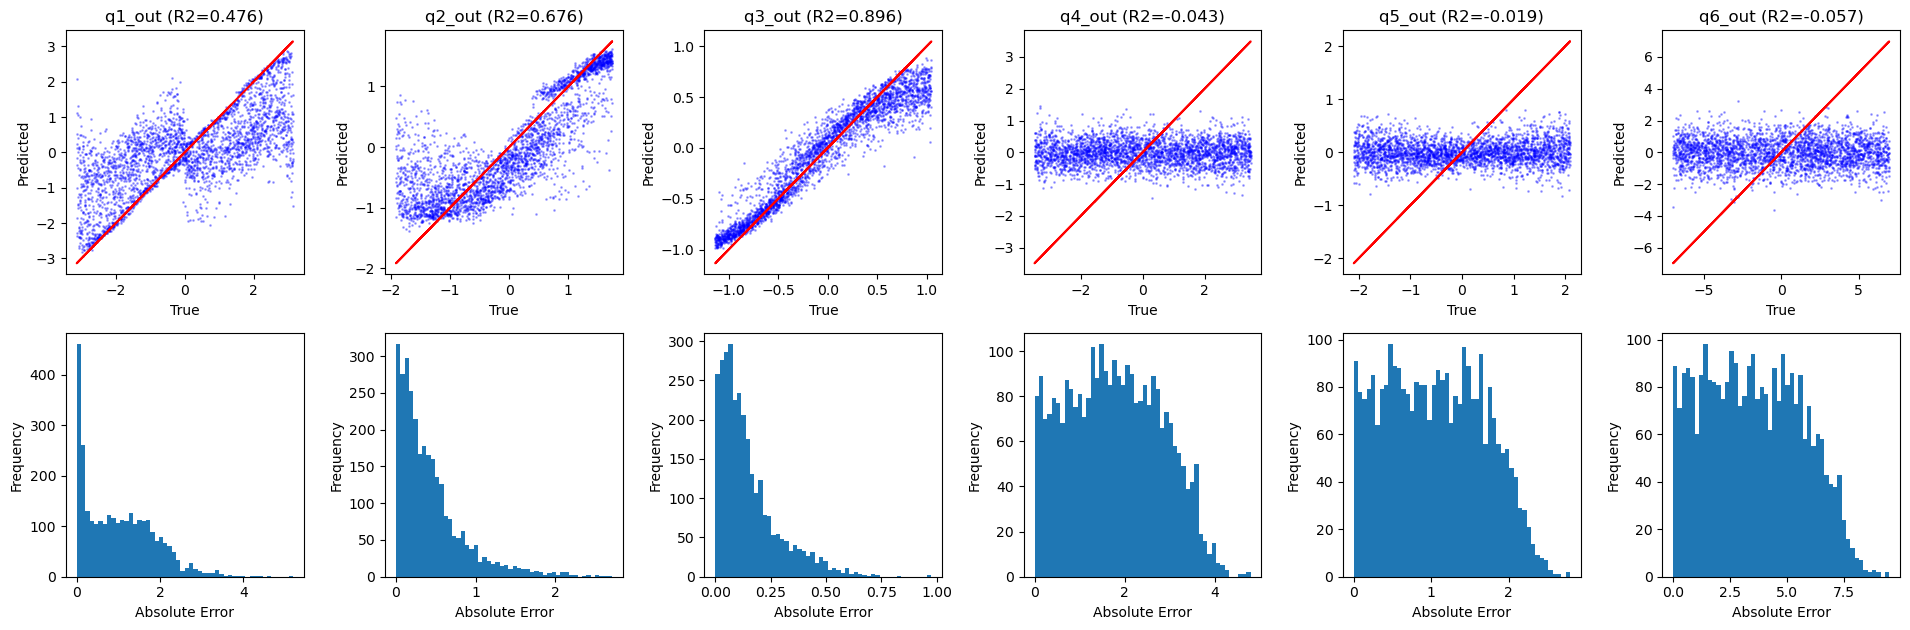

In [ ]:
from sklearn.ensemble import RandomForestRegressor

grid = {'n_estimators': [300], 'max_features': [2, 3, 4, 6]}
M = GridSearchCV(estimator=RandomForestRegressor(), param_grid=grid, cv=3,
                  scoring='neg_mean_absolute_error')
M.fit(x_train, y_train)
print('max_features best:', M.best_params_['max_features'])
log_result('Random Forest', M, x_test, y_test);

Grid search on a 2,000-row subset (6 independent boosted models per candidate)...
Best params: {'estimator__learning_rate': 0.05}
Refitting best config on the full training set...
--- Gradient Boosting ---
MAE: 1.3342
MSE: 4.0149
R2: 0.3342
  q1_out R2: 0.4059
  q2_out R2: 0.6534
  q3_out R2: 0.9751
  q4_out R2: -0.0119
  q5_out R2: -0.0084
  q6_out R2: -0.0087


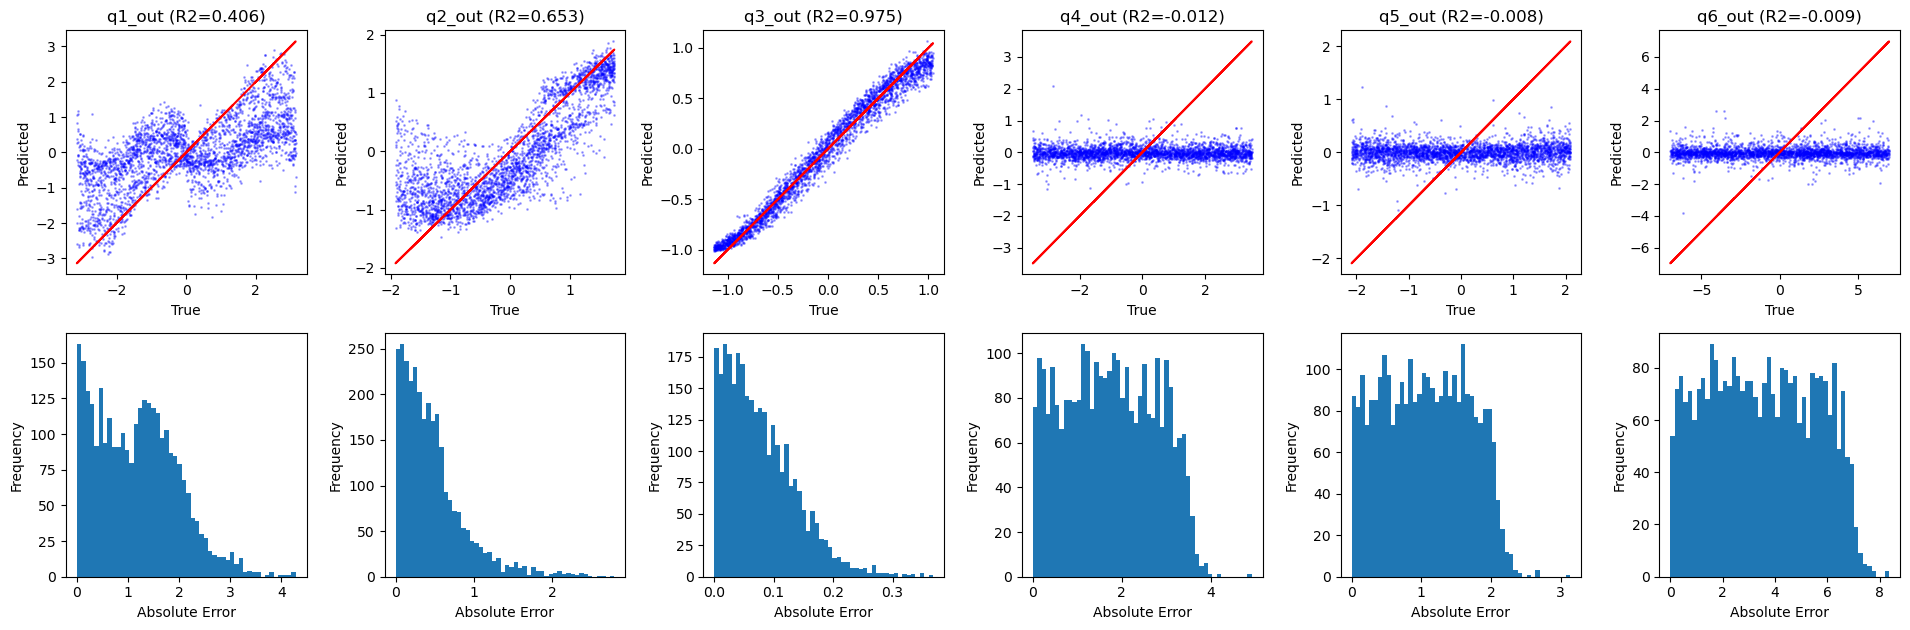

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor

gb_estimator = MultiOutputRegressor(GradientBoostingRegressor(n_estimators=300))
grid = {'estimator__learning_rate': [0.005, 0.01, 0.05, 0.1]}
M = GridSearchCV(estimator=gb_estimator, param_grid=grid, cv=3,
                  scoring='neg_mean_absolute_error')

print("Grid search on a 2,000-row subset (6 independent boosted models per candidate)...")
M.fit(x_train[:2000], y_train[:2000])
print("Best params:", M.best_params_)

print("Refitting best config on the full training set...")
best_gb = M.best_estimator_
best_gb.fit(x_train, y_train)
log_result('Gradient Boosting', best_gb, x_test, y_test);

## Results

In [ ]:
summary_rows = []
for name, r in results.items():
    row = {'Model': name, 'R2': r['R2'], 'MAE': r['MAE'], 'MSE': r['MSE']}
    row.update({f'R2 {j}': v for j, v in r['R2_per_joint'].items()})
    summary_rows.append(row)
summary_df = pd.DataFrame(summary_rows).set_index('Model')
summary_df

,R2,MAE,MSE,R2 q1_out,R2 q2_out,R2 q3_out,R2 q4_out,R2 q5_out,R2 q6_out
Model,,,,,,,,,
Ridge,0.108466,1.458253,4.229993,0.123499,0.529681,0.001108,-0.003797,0.001080,-0.000777
Kernel Ridge (RBF),0.297976,1.357007,4.135682,0.294951,0.598689,0.983407,-0.036724,-0.033875,-0.018593
SVR (RBF),0.287654,1.307608,4.156773,0.350236,0.608522,0.988889,-0.046147,-0.149793,-0.025779
Decision Tree,0.248267,1.372020,4.401937,0.365178,0.598562,0.725437,-0.052115,-0.023494,-0.123964
Random Forest,0.321474,1.327884,4.130030,0.476206,0.676090,0.896487,-0.043467,-0.019101,-0.057368
Gradient Boosting,0.334235,1.334207,4.014895,0.405948,0.653373,0.975107,-0.011915,-0.008357,-0.008745


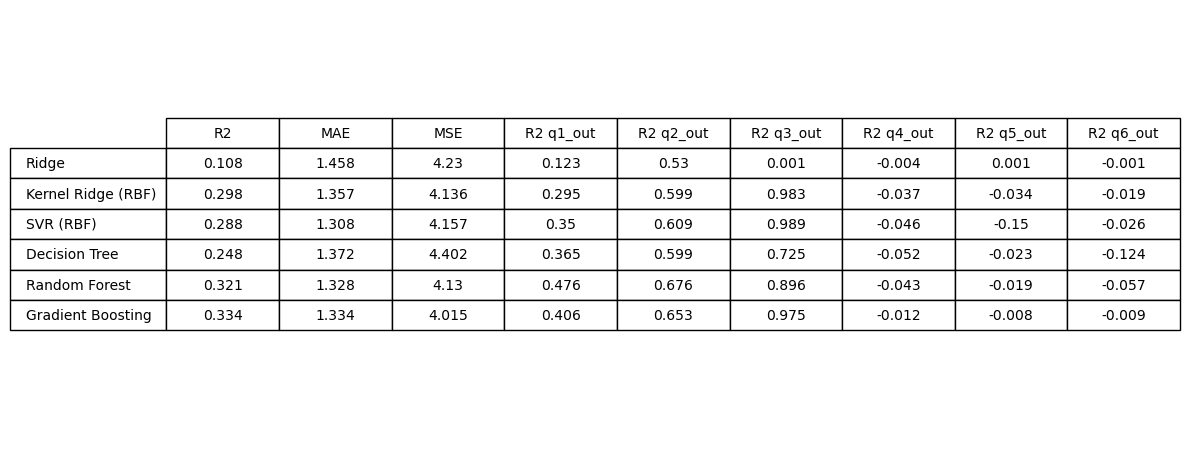

In [ ]:
fig, ax = plt.subplots(figsize=(12, 0.6 * len(summary_df) + 1))
ax.axis('off')
tbl = ax.table(cellText=summary_df.round(3).values,
               rowLabels=summary_df.index,
               colLabels=summary_df.columns,
               cellLoc='center', loc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(10)
tbl.scale(1, 1.5)
fig.tight_layout()
fig.savefig('results_summary_table.png', dpi=200, bbox_inches='tight')

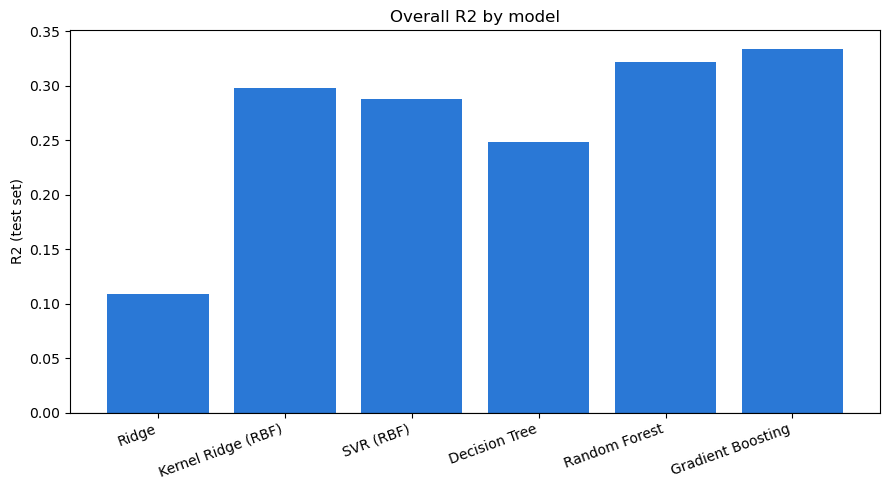

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
names = list(results.keys())
values = [results[n]['R2'] for n in names]
ax.bar(names, values, color='#2a78d6')
ax.set_ylabel('R2 (test set)')
ax.set_title('Overall R2 by model')
ax.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=20, ha='right')
fig.tight_layout()
fig.savefig('results_overall_r2.png', dpi=200, bbox_inches='tight')

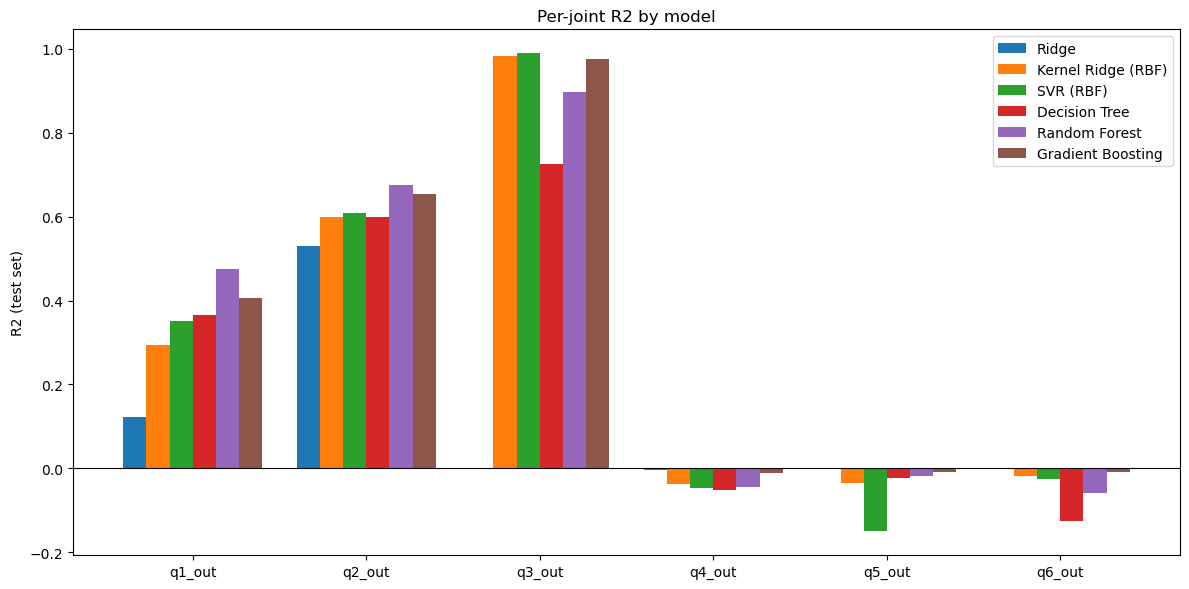

In [ ]:
joints = list(next(iter(results.values()))['R2_per_joint'].keys())
n_models = len(results)
n_joints = len(joints)
x = np.arange(n_joints)
width = 0.8 / n_models

fig, ax = plt.subplots(figsize=(12, 6))
for i, (name, r) in enumerate(results.items()):
    vals = [r['R2_per_joint'][j] for j in joints]
    ax.bar(x + i * width, vals, width, label=name)
ax.set_xticks(x + width * (n_models - 1) / 2)
ax.set_xticklabels(joints)
ax.set_ylabel('R2 (test set)')
ax.set_title('Per-joint R2 by model')
ax.axhline(0, color='black', linewidth=0.8)
ax.legend()
fig.tight_layout()
fig.savefig('results_per_joint_r2.png', dpi=200, bbox_inches='tight')